### Q8: can we fix overconfidence by training with noise?
Temperature scaling tries to fix confidence after training. Here we try to fix the cause:
each training batch gets white or real background noise at a random SNR between 0 and 20 dB (`make_augment` in `src/data.py`).
Then we compare with the model trained on clean audio only.

White and real noise are seen in training, so improvement there is expected.
ESC-50 noise is never seen in training, so it is the fair test of whether the model became more robust in general.

Checkpoint selection still uses clean validation loss. Uses the clean-trained logits from Q6 (trains them if missing).

In [1]:
import os
import sys
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import extra
import metrics
from data import CONDITIONS, EXTRA_CONDITIONS, make_augment

W1117 17:31:54.773000 96416 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
COLORS = {'rf': 'tab:gray', 'cnn': 'tab:blue', 'resnet': 'tab:orange', 'wav2vec': 'tab:green'}
DATASETS = ['esc10', 'sc', 'sc_small']

SEED = 0
WAV2VEC_ESC10 = True  # about 1 hour per model
WAV2VEC_SC = False  # about 1.5 hours per model
RUNS = (
    [('esc10', m) for m in ['cnn', 'resnet'] + (['wav2vec'] if WAV2VEC_ESC10 else [])]
    + [('sc_small', m) for m in ['cnn', 'resnet', 'wav2vec']]
    + [('sc', m) for m in ['cnn', 'resnet'] + (['wav2vec'] if WAV2VEC_SC else [])]
)

#### Training

In [3]:
for dataset, model in RUNS:
    print(dataset, model, 'clean training', flush=True)
    extra.collect_logits(dataset, model, SEED)
    print(dataset, model, 'noise training', flush=True)
    extra.collect_logits(dataset, model, SEED, augment=make_augment(0, 20, SEED), tag='aug')

tables = {}
for dataset, model in RUNS:
    tables[(dataset, model, 'clean-trained')] = extra.calib_table(extra.collect_logits(dataset, model, SEED))
    tables[(dataset, model, 'noise-trained')] = extra.calib_table(extra.collect_logits(dataset, model, SEED, tag='aug'))

esc10 cnn clean training


esc10 cnn noise training


esc10 resnet clean training


esc10 resnet noise training


esc10 wav2vec clean training


esc10 wav2vec noise training


... (66 outputs left out)

sc cnn clean training


sc cnn noise training


sc resnet clean training


sc resnet noise training


#### Curves over all conditions (solid = clean-trained, dashed = noise-trained)

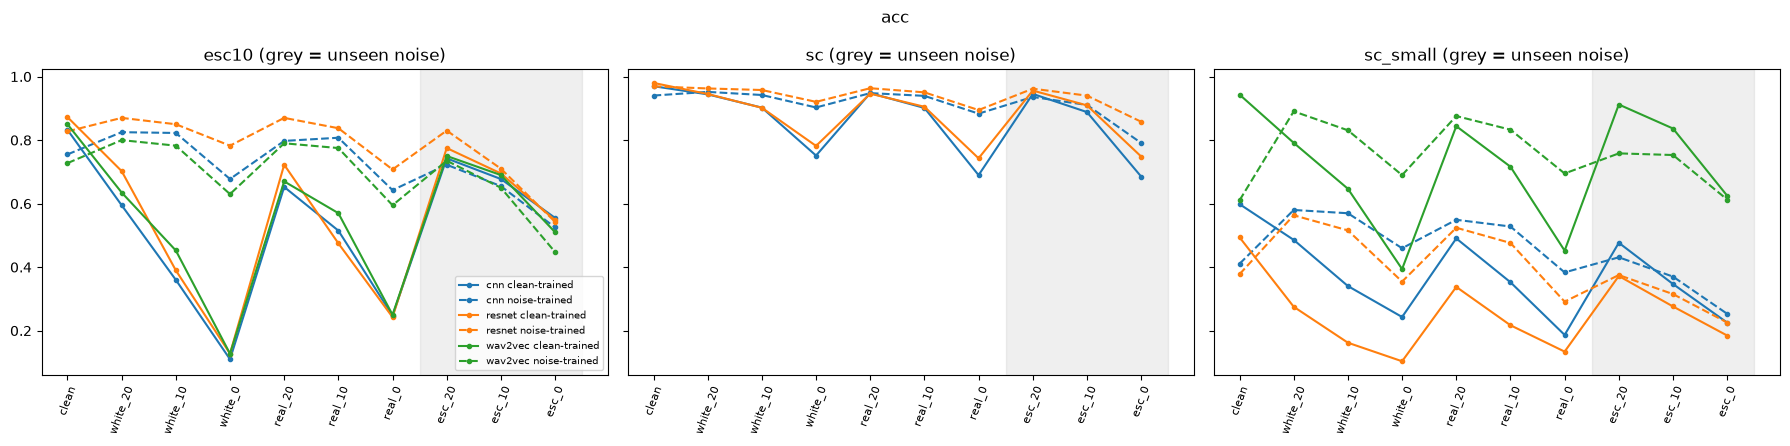

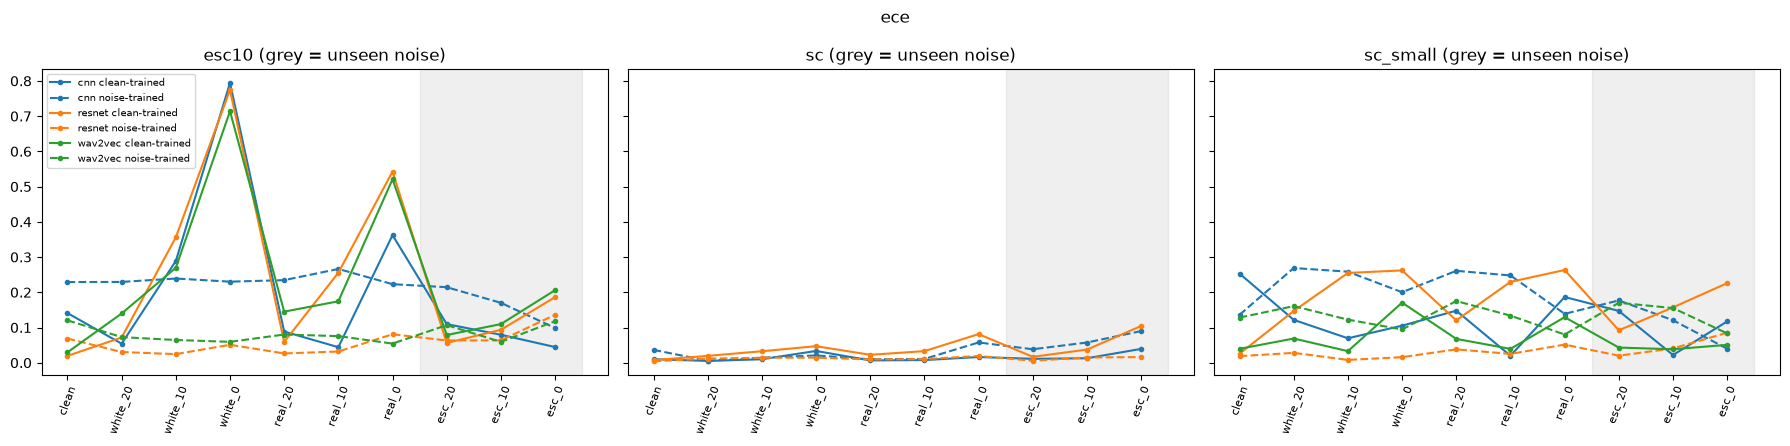

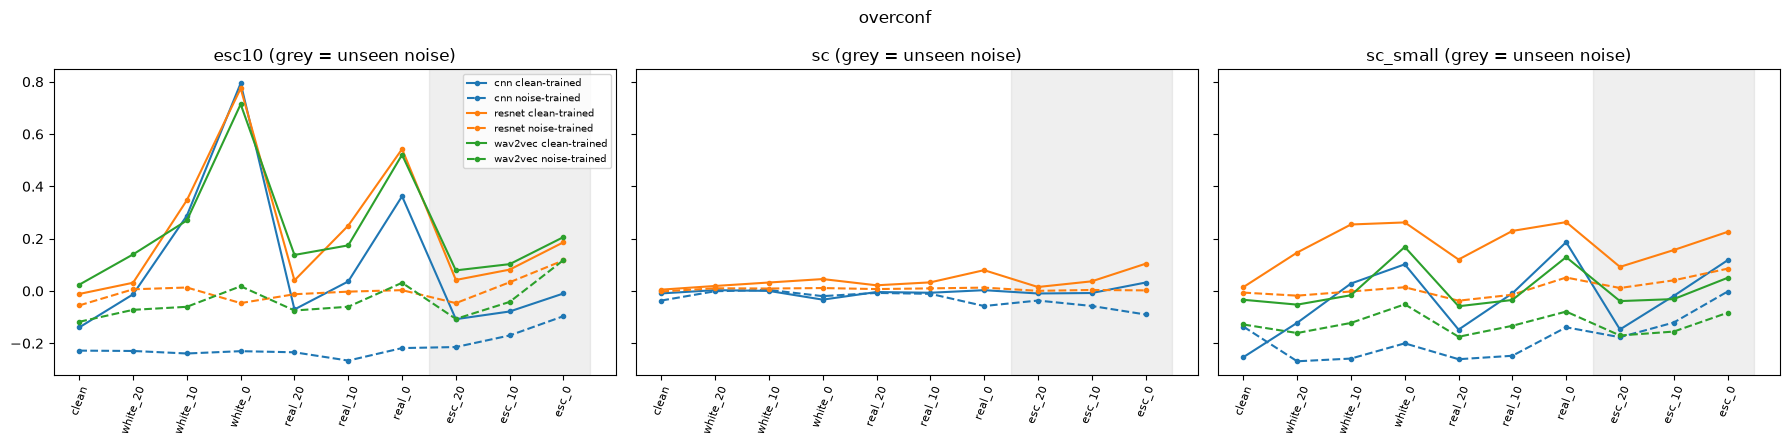

In [4]:
ORDER = extra.ALL_CONDITIONS
STYLE = {'clean-trained': '-', 'noise-trained': '--'}

def curves(metric):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
    for ax, dataset in zip(axes, DATASETS):
        for (d, model, kind), table in tables.items():
            if d == dataset:
                ax.plot(range(len(ORDER)), [table[c][metric] for c in ORDER], STYLE[kind], marker='o', ms=3, color=COLORS[model], label=f'{model} {kind}')
        ax.axvspan(len(CONDITIONS) - 0.5, len(ORDER) - 0.5, color='gray', alpha=0.12)
        ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=70, fontsize=8); ax.set_title(f'{dataset} (grey = unseen noise)')
    axes[0].legend(fontsize=7); fig.suptitle(metric)
    plt.tight_layout(); extra.save(fig, f'q8_{metric}'); plt.show()

curves('acc')
curves('ece')
curves('overconf')

#### Summary: clean, seen noise, unseen noise

In [5]:
def group(condition):
    if condition == 'clean':
        return '1 clean'
    return '3 esc (unseen noise)' if condition.startswith('esc') else '2 white/real (seen)'

rows = []
for (dataset, model, kind), table in tables.items():
    for c, values in table.items():
        rows.append({'dataset': dataset, 'model': model, 'training': kind, 'group': group(c), **values})
summary = pd.DataFrame(rows).groupby(['dataset', 'model', 'group', 'training'])[['acc', 'ece', 'overconf']].mean().unstack('training')
summary.round(3)

acc                \
training                              clean-trained noise-trained   
dataset  model   group                                              
esc10    cnn     1 clean                      0.832         0.755   
                 2 white/real (seen)          0.413         0.762   
                 3 esc (unseen noise)         0.658         0.634   
         resnet  1 clean                      0.872         0.828   
                 2 white/real (seen)          0.443         0.820   
                 3 esc (unseen noise)         0.672         0.694   
         wav2vec 1 clean                      0.850         0.728   
                 2 white/real (seen)          0.451         0.729   
                 3 esc (unseen noise)         0.650         0.611   
sc       cnn     1 clean                      0.970         0.940   
                 2 white/real (seen)          0.856         0.928   
                 3 esc (unseen noise)         0.840         0.879   
         resnet  1 clean                      0.980         0.969   
                 2 white/real (seen)          0.870         0.942   
                 3 esc (unseen noise)         0.871         0.920   
sc_small cnn     1 clean                      0.598         0.411   
                 2 white/real (seen)          0.350         0.512   
                 3 esc (unseen noise)         0.350         0.351   
         resnet  1 clean                      0.494         0.378   
                 2 white/real (seen)          0.205         0.454   
                 3 esc (unseen noise)         0.278         0.305   
         wav2vec 1 clean                      0.943         0.610   
                 2 white/real (seen)          0.641         0.802   
                 3 esc (unseen noise)         0.791         0.708   

                                                ece                \
training                              clean-trained noise-trained   
dataset  model   group                                              
esc10    cnn     1 clean                      0.141         0.229   
                 2 white/real (seen)          0.272         0.237   
                 3 esc (unseen noise)         0.078         0.161   
         resnet  1 clean                      0.020         0.069   
                 2 white/real (seen)          0.343         0.041   
                 3 esc (unseen noise)         0.112         0.088   
         wav2vec 1 clean                      0.029         0.120   
                 2 white/real (seen)          0.327         0.068   
                 3 esc (unseen noise)         0.131         0.095   
sc       cnn     1 clean                      0.010         0.037   
                 2 white/real (seen)          0.013         0.020   
                 3 esc (unseen noise)         0.021         0.062   
         resnet  1 clean                      0.007         0.004   
                 2 white/real (seen)          0.039         0.013   
                 3 esc (unseen noise)         0.053         0.012   
sc_small cnn     1 clean                      0.253         0.136   
                 2 white/real (seen)          0.108         0.229   
                 3 esc (unseen noise)         0.095         0.112   
         resnet  1 clean                      0.026         0.019   
                 2 white/real (seen)          0.213         0.028   
                 3 esc (unseen noise)         0.158         0.049   
         wav2vec 1 clean                      0.040         0.128   
                 2 white/real (seen)          0.085         0.128   
                 3 esc (unseen noise)         0.044         0.136   

                                           overconf                
training                              clean-trained noise-trained  
dataset  model   group                                             
esc10    cnn     1 clean                     -0.139        -0.228  
                 2 white/real (seen)          0.

Things to check: (1) does clean accuracy drop when training with noise (the price), (2) how much ECE falls on seen noise,
(3) whether the gain carries over to the unseen ESC noise, and (4) whether the pattern differs between ESC-10 and Speech Commands.